<a href="https://colab.research.google.com/github/Soupramed/Projek_UAS_kelompok4/blob/main/UAS_Buah_Cepat_Resume.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# UAS Praktikum AI — Klasifikasi Buah Segar dan Busuk

**Notebook lengkap dengan checkpoint dan pengaturan lebih ringan**  
Kelompok: 03

Dataset: [Fruits fresh and rotten for classification](https://www.kaggle.com/datasets/sriramr/fruits-fresh-and-rotten-for-classification). Model: CNN sederhana, MobileNetV2, dan ResNet50 menggunakan TensorFlow/Keras.

### Cara menggunakan dan melanjutkan
1. Buka notebook di Google Colab, pilih GPU jika tersedia, dan klik **Runtime > Run all**.
2. Hubungkan **akun Google Drive yang sama** setiap kali. Nama folder run ditetapkan di bagian 6; jangan mengubahnya ketika melanjutkan.
3. Setelah runtime terputus, buka notebook yang sama, hubungkan Drive yang sama, lalu jalankan kembali dari atas. Data mungkin harus diunduh dan diverifikasi ulang, tetapi pelatihan akan membaca checkpoint dari Drive. Jangan ubah model, pembagian data, seed, ukuran batch, atau konfigurasi saat melanjutkan.
4. Model yang sudah selesai akan dilewati. Model yang terputus dilanjutkan dari **checkpoint paling akhir**, maksimal 25 batch sebelumnya. Jika belum ada checkpoint pertama, model itu mulai dari awal.
5. Saat seluruh proses selesai, simpan notebook dengan output di Drive dan atur akses link untuk aslab. Folder run berisi model, pembagian data, metrik, grafik, diagram, dan analisis untuk PPT.

**Penting:** mekanisme checkpoint batch berlaku sejak notebook ini dijalankan. Notebook lama tidak menyimpan posisi batch, sehingga sisa pelatihan dari runtime lama tidak dapat dipulihkan persis. Folder ini terpisah dari hasil lama, sehingga tidak menimpanya.

Pembagian training, validation, dan testing didasarkan pada kelompok nama gambar asal untuk mengurangi kebocoran antarversi transformasi. Identitas berdasarkan nama tidak menjamin semua gambar yang mirip telah terdeteksi. Hasil metrik hanya tersedia setelah pelatihan dan evaluasi selesai.

### Pengaturan untuk mengurangi waktu
Semua arsitektur memakai input **160 × 160**, batch size **32**, maksimal **6 epoch**, dan early stopping dengan patience **2**. MobileNetV2 dan ResNet50 memakai backbone ImageNet yang dibekukan. Pengaturan ini mempertahankan seluruh gambar dan syarat minimal tiga model, tetapi waktu selesai **tidak dijamin satu jam** dan pelatihan yang lebih singkat dapat menghasilkan performa lebih rendah. Unduhan, pemeriksaan file, validation, penyimpanan, dan evaluasi menambah waktu.

Notebook ini memulai **run baru**. Model dan checkpoint dari notebook lama dengan input 224 × 224 tidak otomatis menjadi checkpoint batch notebook ini. Setelah run baru berjalan, checkpoint memungkinkan pelatihan dilanjutkan dari batch yang tersimpan.


## 1. Instalasi dan pengaturan lingkungan
Colab umumnya sudah memiliki TensorFlow. Sel berikut memasang paket yang belum tersedia. Model pretrained memerlukan internet untuk mengunduh bobot ImageNet.

In [ ]:
import importlib.util, subprocess, sys
paket = {'kagglehub': 'kagglehub', 'tensorflow': 'tensorflow', 'sklearn': 'scikit-learn',
         'PIL': 'Pillow', 'matplotlib': 'matplotlib', 'pandas': 'pandas'}
kurang = [nama for modul, nama in paket.items() if importlib.util.find_spec(modul) is None]
if kurang:
    subprocess.check_call([sys.executable, '-m', 'pip', 'install', '-q', *kurang])
print('Paket siap.')

Paket siap.


In [ ]:
import base64, gzip, hashlib, io, json, os, re, shutil, time, uuid
from datetime import datetime, timezone
from pathlib import Path, PurePosixPath
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
import kagglehub
import sklearn
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import confusion_matrix, classification_report
import tensorflow as tf
from tensorflow.keras import layers, models
from IPython.display import display

SEED = 42
SIZE = (160, 160)
BATCH_SIZE = 32
MAX_EPOCH = 6
PATIENCE = 2
tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
print('TensorFlow:', tf.__version__, '| scikit-learn:', sklearn.__version__)
print('GPU:', tf.config.list_physical_devices('GPU'))

TensorFlow: 2.21.0 | scikit-learn: 1.6.1
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 2. Muat manifest preprocessing sebelumnya
Manifest ini berasal dari `hasil_preprocessing_buah/manifest_semua.csv` milik kelompok. Isinya path relatif, label, dan hash untuk 13.599 gambar. Data gambar sebenarnya diunduh pada langkah berikutnya.

In [ ]:
#@title Muat manifest preprocessing sebelumnya (data tertanam)
MANIFEST_B64 = """..."""
manifest_bytes = gzip.decompress(base64.b64decode(MANIFEST_B64))
expected_manifest_hash = '95145ab7fb783349970b7957129e70a3cfbb259aa5344aff3111500f86d219a3'
if hashlib.sha256(manifest_bytes).hexdigest() != expected_manifest_hash:
    raise ValueError('Manifest tidak utuh. Unduh kembali notebook aslinya.')
manifest = pd.read_csv(io.BytesIO(manifest_bytes))
print('Jumlah gambar pada manifest:', len(manifest))
display(manifest.head(3))

Jumlah gambar pada manifest: 13599


,relative_path,class_name,label,original_split,split,sha256
0,dataset/train/freshoranges/rotated_by_60_Scree...,freshoranges,2,train,train,94858e13883d0b6e2ecdb27b99556612622baff86a87e1...
1,dataset/train/rottenoranges/translation_Screen...,rottenoranges,5,train,train,c8839b4415e2bf300042f9dc01759a6ac5bccf1b5d2982...
2,dataset/train/rottenapples/translation_Screen ...,rottenapples,3,train,train,83ec8722a28c9bb9d2a5fd410d5815c46c080937900ea0...


## 3. Unduh dan verifikasi dataset
Dataset versi 1 digunakan agar sesuai dengan hasil preprocessing sebelumnya. Hash setiap gambar dibandingkan dengan manifest; sel berhenti jika file hilang atau berubah. Pemeriksaan dapat memakan beberapa menit.

In [ ]:
dataset_root = Path(kagglehub.dataset_download(
    'sriramr/fruits-fresh-and-rotten-for-classification/versions/1'
)).resolve()
print('Folder dataset:', dataset_root)

class_names = ['freshapples', 'freshbanana', 'freshoranges',
               'rottenapples', 'rottenbanana', 'rottenoranges']
class_to_index = {name: index for index, name in enumerate(class_names)}
required = {'relative_path', 'class_name', 'label', 'sha256', 'split'}
if not required.issubset(manifest.columns):
    raise ValueError('Kolom manifest tidak lengkap.')
if len(manifest) != 13599 or manifest.relative_path.duplicated().any():
    raise ValueError('Jumlah atau path manifest tidak sesuai.')
if set(manifest.class_name) != set(class_names) or not (manifest.label == manifest.class_name.map(class_to_index)).all():
    raise ValueError('Label atau nama kelas pada manifest tidak sesuai.')

def file_sha256(path):
    digest = hashlib.sha256()
    with path.open('rb') as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b''):
            digest.update(block)
    return digest.hexdigest()

masalah = []
for no, row in enumerate(manifest.itertuples(index=False), 1):
    lokasi = (dataset_root / row.relative_path).resolve()
    if not lokasi.is_relative_to(dataset_root) or not lokasi.is_file():
        masalah.append((row.relative_path, 'path tidak ada atau di luar dataset'))
    elif file_sha256(lokasi) != row.sha256:
        masalah.append((row.relative_path, 'hash berbeda'))
    if no % 2000 == 0 or no == len(manifest):
        print(f'Diperiksa {no:,}/{len(manifest):,}')
if masalah:
    print('Contoh masalah:', masalah[:10])
    raise RuntimeError(f'{len(masalah)} gambar tidak sesuai dengan manifest.')
print('Semua file sesuai manifest.')

Using Colab cache for faster access to the 'fruits-fresh-and-rotten-for-classification' dataset.
Folder dataset: /kaggle/input/fruits-fresh-and-rotten-for-classification
Diperiksa 2,000/13,599
Diperiksa 4,000/13,599
Diperiksa 6,000/13,599
Diperiksa 8,000/13,599
Diperiksa 10,000/13,599
Diperiksa 12,000/13,599
Diperiksa 13,599/13,599
Semua file sesuai manifest.


## 4. Eksplorasi enam kelas
Tabel menunjukkan jumlah pada dataset sebelum pembagian baru. Gambar contoh dipilih dari manifest, sehingga hanya menampilkan data yang telah diperiksa.

,jumlah_gambar
class_name,
freshapples,2088
freshbanana,1962
freshoranges,1854
rottenapples,2943
rottenbanana,2754
rottenoranges,1998


Total: 13599


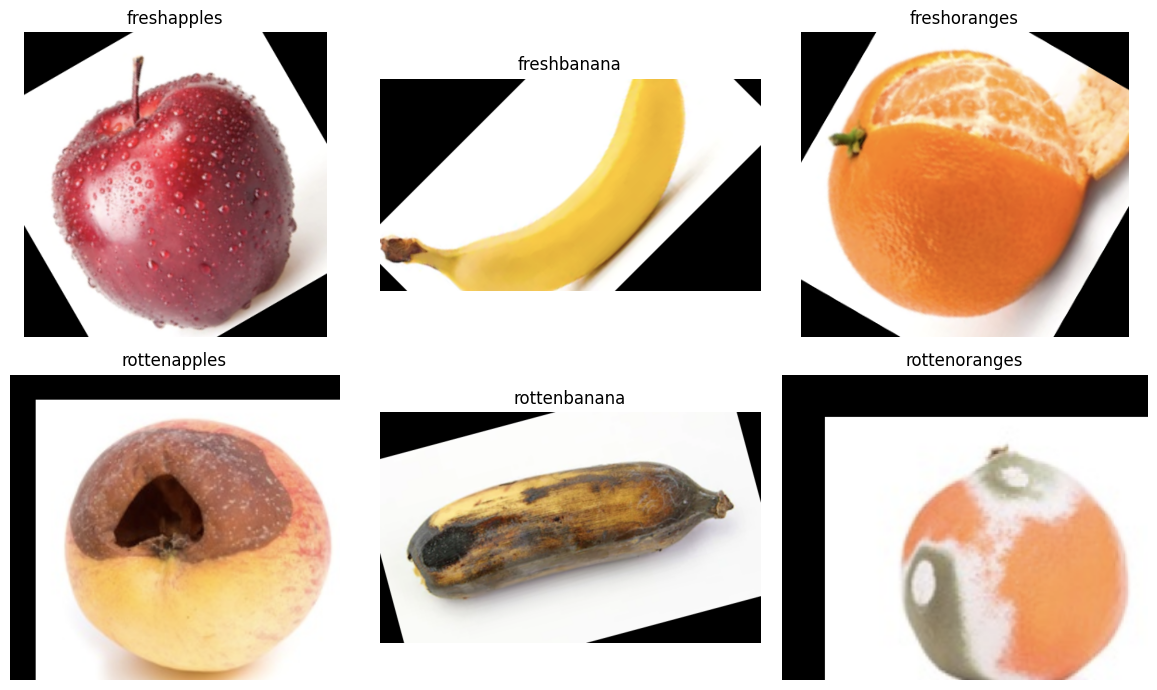

In [ ]:
jumlah_awal = manifest.groupby('class_name').size().reindex(class_names)
display(jumlah_awal.to_frame('jumlah_gambar'))
print('Total:', jumlah_awal.sum())
fig, axes = plt.subplots(2, 3, figsize=(12, 7))
for ax, name in zip(axes.flat, class_names):
    row = manifest[manifest.class_name == name].iloc[0]
    with Image.open(dataset_root / row.relative_path) as img:
        ax.imshow(img.convert('RGB'))
    ax.set_title(name); ax.axis('off')
plt.tight_layout(); plt.show()

## 5. Bagi ulang berdasarkan gambar asal
Prefix `rotated_by_*`, `vertical_flip`, `translation`, dan `saltandpepper` menunjukkan transformasi. Prefix dihapus untuk memperoleh perkiraan identitas gambar asal, lalu seluruh versinya dimasukkan ke satu bagian. Pembagian dua tahap menggunakan `StratifiedGroupKFold` dengan seed tetap: sekitar 64% training, 16% validation, dan 20% testing. Stratifikasi mempertahankan proporsi kelas sedekat mungkin sambil menjaga kelompok tidak tumpang tindih.

Pembagian baru menggantikan folder test bawaan karena versi dari satu foto terindikasi tersebar di folder train dan test asli. Pemisahan berdasarkan nama mengurangi kebocoran yang terdeteksi, tetapi gambar yang mirip dengan nama berbeda masih mungkin ada. [Dokumentasi StratifiedGroupKFold](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.StratifiedGroupKFold.html).

Kelompok nama asal yang sebelumnya muncul di train dan test: 1310


split,train,validation,test,total
class_name,,,,
freshapples,1350,324,414,2088
freshbanana,1251,315,396,1962
freshoranges,1179,306,369,1854
rottenapples,1872,477,594,2943
rottenbanana,1764,441,549,2754
rottenoranges,1278,315,405,1998


Jumlah: {'train': 8694, 'test': 2727, 'validation': 2178}
Kelompok gambar asal: 1511


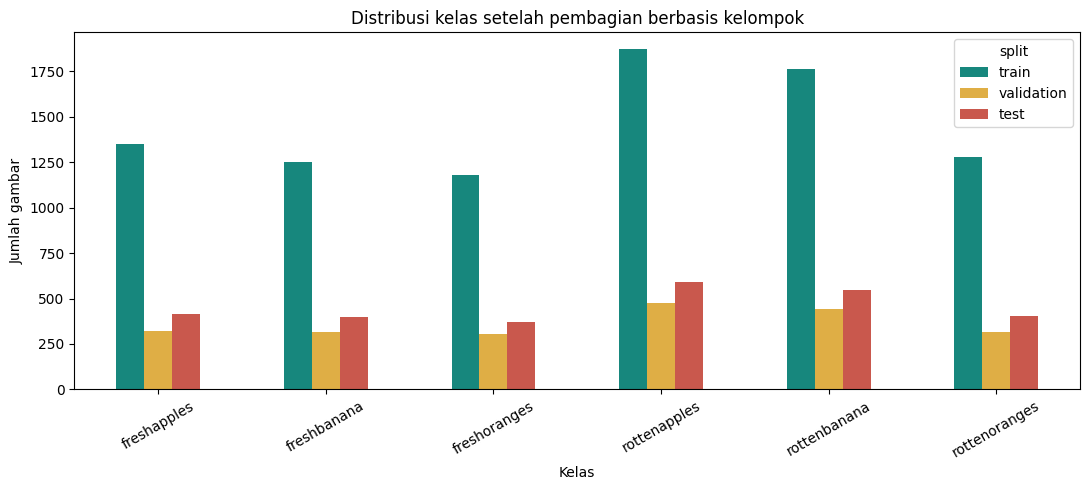

In [ ]:
def nama_asal(rel):
    nama = PurePosixPath(rel).name
    return re.sub(r'^(?:rotated_by_\d+_|vertical_flip_|horizontal_flip_|translation_|saltandpepper_)', '', nama, flags=re.I)

manifest['kelompok_asal'] = manifest.relative_path.map(nama_asal)
if (manifest.groupby('kelompok_asal').class_name.nunique() > 1).any():
    raise ValueError('Satu nama asal muncul pada beberapa label; perlu pemeriksaan manual.')
if manifest.sha256.duplicated().any():
    raise ValueError('Ada file identik pada manifest; periksa sebelum membuat split.')

old_groups = manifest.groupby('kelompok_asal')['split'].agg(set)
print('Kelompok nama asal yang sebelumnya muncul di train dan test:',
      sum('train' in s and 'test' in s for s in old_groups))
split_test = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED)
idx_trainval, idx_test = next(split_test.split(manifest, manifest.label, manifest.kelompok_asal))
trainval = manifest.iloc[idx_trainval].copy()
split_val = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=SEED + 1)
idx_train, idx_val = next(split_val.split(trainval, trainval.label, trainval.kelompok_asal))
train_df = trainval.iloc[idx_train].copy().assign(split='train')
val_df = trainval.iloc[idx_val].copy().assign(split='validation')
test_df = manifest.iloc[idx_test].copy().assign(split='test')
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert set(a.kelompok_asal).isdisjoint(set(b.kelompok_asal))
    assert set(a.sha256).isdisjoint(set(b.sha256))
assert len(train_df) + len(val_df) + len(test_df) == len(manifest)
assert all(set(part.class_name) == set(class_names) for part in [train_df, val_df, test_df])
manifest_baru = pd.concat([train_df, val_df, test_df], ignore_index=True)
distribusi = pd.crosstab(manifest_baru.class_name, manifest_baru['split']).reindex(
    index=class_names, columns=['train', 'validation', 'test'], fill_value=0)
display(distribusi.assign(total=distribusi.sum(axis=1)))
print('Jumlah:', manifest_baru['split'].value_counts().to_dict())
print('Kelompok gambar asal:', manifest_baru.kelompok_asal.nunique())
ax = distribusi.plot.bar(figsize=(11, 5), rot=30, color=['#17877d', '#dfae45', '#c9584d'])
ax.set(xlabel='Kelas', ylabel='Jumlah gambar', title='Distribusi kelas setelah pembagian berbasis kelompok')
plt.tight_layout(); plt.show()

## 6. Hubungkan Drive dan pilih folder run
Nama `RUN_NAME` di bawah dibuat khusus untuk notebook ini. Jangan mengubahnya saat melanjutkan, karena checkpoint disimpan di folder tersebut. Untuk eksperimen baru, ubah nama setelah mencatat folder lama. Jangan menjalankan dua runtime untuk folder run yang sama secara bersamaan.

Dataset dan output sementara di Colab dapat terhapus saat runtime berakhir. Karena itu dataset mungkin perlu diunduh dan diverifikasi kembali; checkpoint dan hasil model disimpan di Drive.

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

# Gunakan nama ini lagi setelah runtime terputus. Jangan mengubahnya saat resume.
RUN_NAME = 'buah_cepat_resume_daf3a93e2d'
folder_hasil = Path('/content/drive/MyDrive/UAS_AI') / RUN_NAME
folder_hasil.mkdir(parents=True, exist_ok=True)
print('Folder run:', folder_hasil)

# Jika sudah ada, pastikan split yang dibuat ulang identik dengan split awal.
split_paths = {name: folder_hasil / f'{name}.csv' for name in ['train', 'validation', 'test']}
existing = [path.exists() for path in split_paths.values()]
if any(existing) and not all(existing):
    raise RuntimeError('CSV pembagian di Drive tidak lengkap. Jangan lanjutkan sebelum diperiksa.')
if all(existing):
    for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
        old = pd.read_csv(split_paths[name])
        cols = ['relative_path', 'class_name', 'label', 'sha256', 'kelompok_asal', 'split']
        baru = frame[cols].sort_values('relative_path').reset_index(drop=True)
        lama = old[cols].sort_values('relative_path').reset_index(drop=True)
        if not baru.equals(lama):
            raise RuntimeError(f'Pembagian {name} berbeda dengan run sebelumnya. Hentikan dan periksa versi dataset/library.')
    print('Pembagian data identik dengan run sebelumnya.')
else:
    for name, frame in [('train', train_df), ('validation', val_df), ('test', test_df)]:
        frame[['relative_path', 'class_name', 'label', 'sha256', 'kelompok_asal', 'split']].to_csv(split_paths[name], index=False)
    manifest_baru.to_csv(folder_hasil / 'manifest_pembagian_baru.csv', index=False)
    with (folder_hasil / 'label_kelas.json').open('w', encoding='utf-8') as f:
        json.dump(class_to_index, f, indent=2, ensure_ascii=False)

konfigurasi = {'dataset': 'sriramr/fruits-fresh-and-rotten-for-classification/versions/1',
               'seed': SEED, 'size': list(SIZE), 'batch_size': BATCH_SIZE, 'max_epoch': MAX_EPOCH,
               'patience': PATIENCE, 'tensorflow': tf.__version__, 'sklearn': sklearn.__version__,
               'counts': manifest_baru['split'].value_counts().to_dict(),
               'split': 'StratifiedGroupKFold twice; group = filename without augmentation prefix',
               'augmentasi_training': 'stateless horizontal flip dan brightness',
               'checkpoint_interval_batch': 25}
config_path = folder_hasil / 'konfigurasi.json'
if config_path.exists():
    with config_path.open(encoding='utf-8') as f:
        if json.load(f) != konfigurasi:
            raise RuntimeError('Konfigurasi berbeda dengan run sebelumnya. Gunakan runtime/library yang sama atau buat run baru.')
else:
    with config_path.open('w', encoding='utf-8') as f:
        json.dump(konfigurasi, f, indent=2, ensure_ascii=False)

Mounted at /content/drive
Folder run: /content/drive/MyDrive/UAS_AI/buah_cepat_resume_daf3a93e2d


## 7. Pipeline gambar
Gambar diproses sebagai RGB 160 × 160. Validation dan test tidak diaugmentasi. Training menggunakan flip horizontal dan perubahan kecerahan acak **stateless** yang ditentukan oleh seed, nomor epoch, dan identitas gambar, sehingga urutan dan augmentasi dapat dibangun kembali setelah terputus. Resize langsung dapat mengubah rasio aspek.

Preprocessing khusus tiap arsitektur berada di pipeline, bukan dalam berkas model `.keras`. Gunakan preprocessing yang sama saat evaluasi.

In [ ]:
AUTOTUNE = tf.data.AUTOTUNE

def baca_gambar(path, label):
    image = tf.io.decode_image(tf.io.read_file(path), channels=3, expand_animations=False)
    image.set_shape([None, None, 3])
    image = tf.image.resize(image, SIZE)
    return tf.cast(image, tf.float32), tf.cast(label, tf.int32)

def buat_dataset(frame, training=False):
    if training:
        raise ValueError('Gunakan dataset_epoch untuk training yang dapat dilanjutkan.')
    paths = [str(dataset_root / rel) for rel in frame.relative_path]
    ds = tf.data.Dataset.from_tensor_slices((paths, frame.label.to_numpy(dtype='int32')))
    return ds.map(baca_gambar, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE).prefetch(AUTOTUNE)

val_ds = buat_dataset(val_df)
test_ds = buat_dataset(test_df)

def pp_cnn(x, y): return x / 255.0, y
def pp_mobilenet(x, y): return tf.keras.applications.mobilenet_v2.preprocess_input(x), y
def pp_resnet(x, y): return tf.keras.applications.resnet50.preprocess_input(x), y
preprocessors = {'CNN': pp_cnn, 'MobileNetV2': pp_mobilenet, 'ResNet50': pp_resnet}

def untuk_model(ds, nama):
    return ds.map(preprocessors[nama], num_parallel_calls=AUTOTUNE).prefetch(AUTOTUNE)

def dataset_epoch(frame, epoch, mulai_batch, nama):
    # Urutan epoch dapat dibangun ulang sama persis setelah restart.
    urutan = np.random.default_rng(SEED + int(epoch)).permutation(len(frame))
    indeks_awal = int(mulai_batch) * BATCH_SIZE
    urutan = urutan[indeks_awal:]
    terpilih = frame.iloc[urutan]
    paths = [str(dataset_root / rel) for rel in terpilih.relative_path]
    ds = tf.data.Dataset.from_tensor_slices((paths, terpilih.label.to_numpy(dtype='int32'), urutan.astype('int32')))
    seed_epoch = np.int32(SEED + int(epoch))
    def baca_dan_augmentasi(path, label, indeks):
        image, label = baca_gambar(path, label)
        seed = tf.stack([seed_epoch, indeks])
        image = tf.image.stateless_random_flip_left_right(image, seed=seed)
        seed_warna = tf.stack([seed_epoch + 10000, indeks])
        image = tf.image.stateless_random_brightness(image, max_delta=12.75, seed=seed_warna)
        image = tf.clip_by_value(image, 0.0, 255.0)
        return image, label
    ds = ds.map(baca_dan_augmentasi, num_parallel_calls=AUTOTUNE).batch(BATCH_SIZE)
    return untuk_model(ds, nama)

gambar, label = next(iter(val_ds))
print('Contoh batch validation:', gambar.shape, '| label:', label.shape)

Contoh batch validation: (32, 160, 160, 3) | label: (32,)


# 3. Implementasi tiga model
CNN dilatih dari awal. MobileNetV2 dan ResNet50 menggunakan pretrained ImageNet sebagai feature extractor yang dibekukan. Kepala klasifikasi enam kelas dilatih menggunakan data training. Perbandingan ini mencampurkan arsitektur dan penggunaan bobot pretrained, jadi perbedaan hasil tidak boleh dianggap semata-mata akibat arsitektur.

In [ ]:
def buat_cnn():
    return models.Sequential([
        layers.Input(shape=(160, 160, 3)),
        layers.Conv2D(32, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(64, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)),
        layers.Conv2D(128, (3, 3), activation='relu'), layers.MaxPooling2D((2, 2)),
        layers.GlobalAveragePooling2D(), layers.Dropout(0.3),
        layers.Dense(128, activation='relu'), layers.Dense(6, activation='softmax')
    ], name='CNN_Sederhana')

def buat_transfer(nama):
    if nama == 'MobileNetV2':
        base = tf.keras.applications.MobileNetV2(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
    elif nama == 'ResNet50':
        base = tf.keras.applications.ResNet50(input_shape=(160, 160, 3), include_top=False, weights='imagenet')
    else:
        raise ValueError('Arsitektur tidak dikenal')
    base.trainable = False
    inputs = tf.keras.Input(shape=(160, 160, 3))
    x = base(inputs, training=False)
    x = layers.GlobalAveragePooling2D()(x)
    x = layers.Dropout(0.3)(x)
    outputs = layers.Dense(6, activation='softmax')(x)
    return tf.keras.Model(inputs, outputs, name=nama + '_Buah')

## 8. Latih model dengan checkpoint pemulihan
Checkpoint kecil disimpan ke Drive setiap 25 batch dan di akhir setiap epoch. Checkpoint menyimpan bobot yang dilatih, kondisi optimizer, nomor epoch dan batch berikutnya, metrik yang telah terkumpul, riwayat, serta kondisi early stopping. Dua checkpoint terakhir disimpan sebagai cadangan. Lapisan dasar pretrained yang dibekukan dimuat ulang dari ImageNet dan diperiksa hash-nya ketika melanjutkan.

Model terbaik tetap disimpan terpisah berdasarkan `val_loss`. Jika runtime terputus di antara dua checkpoint, batch setelah checkpoint terakhir diulang. Kode menggunakan batch loop Keras agar dapat melewati batch yang sudah tercatat dan melanjutkan tanpa mengulang dari epoch pertama. Hasil numerik dapat sedikit berbeda antarperangkat/runtime.

Pengaturan singkat menggunakan maksimal 6 epoch dan patience 2 untuk setiap model. Karena durasi bergantung pada runtime, jaringan, dan Drive, satu jam adalah target perkiraan, bukan batas yang dapat dijamin.


In [ ]:
CHECKPOINT_INTERVAL = 25

def tulis_csv_atomik(df, path):
    temp = path.with_name(path.stem + '.tmp.csv')
    df.to_csv(temp, index=False)
    os.replace(temp, path)

def simpan_json_atomik(obj, path):
    temp = path.with_name(path.stem + '.tmp.json')
    with temp.open('w', encoding='utf-8') as f:
        json.dump(obj, f, indent=2, ensure_ascii=False)
    os.replace(temp, path)

def salin_atomik(source_path, target_path):
    temp = target_path.with_name(target_path.stem + '.tmp.keras')
    shutil.copy2(source_path, temp)
    os.replace(temp, target_path)

def sidik_bobot_beku(model):
    digest = hashlib.sha256()
    for variable in model.non_trainable_variables:
        # State generator acak bukan bobot pretrained yang harus dicocokkan.
        if 'seed_generator' in getattr(variable, 'path', variable.name):
            continue
        digest.update(np.asarray(variable.numpy()).tobytes())
    return digest.hexdigest()

def sudah_selesai(nama):
    marker = folder_hasil / f'metadata_{nama}.json'
    return (marker.is_file() and (folder_hasil / f'{nama}_terbaik.keras').is_file()
            and (folder_hasil / f'history_{nama}.csv').is_file())

def latih_model(nama, model):
    if sudah_selesai(nama):
        print(f'{nama} sudah selesai, menggunakan hasil yang tersimpan.')
        return pd.read_csv(folder_hasil / f'history_{nama}.csv')
    model.compile(optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
                  loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    model.optimizer.build(model.trainable_variables)
    frozen_hash = sidik_bobot_beku(model)
    signature = {'tensorflow': tf.__version__, 'model': nama,
                 'trainable_shapes': [list(v.shape) for v in model.trainable_variables],
                 'frozen_sha256': frozen_hash, 'interval': CHECKPOINT_INTERVAL}
    signature_path = folder_hasil / f'signature_{nama}.json'
    if signature_path.exists():
        with signature_path.open(encoding='utf-8') as f:
            if json.load(f) != signature:
                raise RuntimeError(f'Model atau bobot beku {nama} berbeda dengan checkpoint. Jangan lanjutkan sebelum diperiksa.')
    else:
        simpan_json_atomik(signature, signature_path)
    model.summary()

    # Hanya bobot yang dilatih dan state acak dicadangkan setiap 25 batch.
    tracked_vars = list(model.trainable_variables)
    tracked_vars += [v for v in model.non_trainable_variables
                     if 'seed_generator' in getattr(v, 'path', v.name)]
    weight_state = tf.train.Checkpoint(**{f'variable_{i}': v for i, v in enumerate(tracked_vars)})
    epoch_var = tf.Variable(0, dtype=tf.int64, trainable=False)
    batch_var = tf.Variable(0, dtype=tf.int64, trainable=False)
    loss_sum = tf.Variable(0., dtype=tf.float64, trainable=False)
    acc_sum = tf.Variable(0., dtype=tf.float64, trainable=False)
    sample_count = tf.Variable(0, dtype=tf.int64, trainable=False)
    best_loss = tf.Variable(float('inf'), dtype=tf.float64, trainable=False)
    best_file = tf.Variable('', dtype=tf.string, trainable=False)
    wait_var = tf.Variable(0, dtype=tf.int64, trainable=False)
    done_var = tf.Variable(False, dtype=tf.bool, trainable=False)
    history_json = tf.Variable('[]', dtype=tf.string, trainable=False)
    elapsed_var = tf.Variable(0., dtype=tf.float64, trainable=False)
    checkpoint = tf.train.Checkpoint(weights=weight_state, optimizer=model.optimizer,
        epoch=epoch_var, batch=batch_var, loss_sum=loss_sum, acc_sum=acc_sum,
        sample_count=sample_count, best_loss=best_loss, best_file=best_file,
        wait=wait_var, done=done_var, history=history_json, elapsed=elapsed_var)
    manager = tf.train.CheckpointManager(checkpoint, str(folder_hasil / f'resume_{nama}'), max_to_keep=2)
    if manager.latest_checkpoint:
        restored = False
        for backup in reversed(manager.checkpoints):
            try:
                checkpoint.restore(backup).assert_existing_objects_matched()
                print(f'Checkpoint dipulihkan: {backup}')
                restored = True
                break
            except (OSError, ValueError, AssertionError, tf.errors.OpError) as exc:
                print(f'Checkpoint tidak dapat dibaca: {backup} ({exc})')
        if not restored:
            raise RuntimeError(f'Checkpoint {nama} tidak dapat dipulihkan; hasil tidak ditimpa.')
        print(f'Melanjutkan {nama}: epoch {int(epoch_var.numpy()) + 1}, batch berikutnya {int(batch_var.numpy()) + 1}.')
    else:
        print(f'Memulai {nama} dari awal; checkpoint batch tersimpan setiap {CHECKPOINT_INTERVAL} batch.')

    early = tf.keras.callbacks.EarlyStopping(monitor='val_loss', mode='min', patience=PATIENCE,
                                              restore_best_weights=False, verbose=1)
    early.set_model(model)
    early.on_train_begin()
    if int(epoch_var.numpy()) > 0:
        early.best = float(best_loss.numpy())
        early.wait = int(wait_var.numpy())
    total_batch = int(np.ceil(len(train_df) / BATCH_SIZE))
    history_path = folder_hasil / f'history_{nama}.csv'

    while not bool(done_var.numpy()):
        epoch = int(epoch_var.numpy())
        start_batch = int(batch_var.numpy())
        print(f'\n{nama}: epoch {epoch + 1}/{MAX_EPOCH}, mulai batch {start_batch + 1}/{total_batch}')
        ds = dataset_epoch(train_df, epoch, start_batch, nama)
        for batch_no, (x, y) in enumerate(ds, start=start_batch):
            model.reset_metrics()
            start_time = time.perf_counter()
            values = model.train_on_batch(x, y, return_dict=True)
            elapsed_var.assign_add(time.perf_counter() - start_time)
            count = int(tf.shape(y)[0])
            loss_sum.assign_add(float(values['loss']) * count)
            acc_sum.assign_add(float(values['accuracy']) * count)
            sample_count.assign_add(count)
            batch_var.assign(batch_no + 1)
            if (batch_no + 1) % CHECKPOINT_INTERVAL == 0:
                manager.save()
                print(f'Batch {batch_no + 1}/{total_batch} — checkpoint tersimpan', flush=True)
        if int(sample_count.numpy()) != len(train_df):
            raise RuntimeError('Jumlah sampel epoch tidak sesuai; checkpoint dipertahankan untuk pemeriksaan.')

        start_time = time.perf_counter()
        val = model.evaluate(untuk_model(val_ds, nama), verbose=0, return_dict=True)
        elapsed_var.assign_add(time.perf_counter() - start_time)
        row = {'epoch': epoch, 'loss': float(loss_sum.numpy() / sample_count.numpy()),
               'accuracy': float(acc_sum.numpy() / sample_count.numpy()),
               'val_loss': float(val['loss']), 'val_accuracy': float(val['accuracy'])}
        if not np.isfinite(list(row.values())).all():
            raise RuntimeError('Metrik tidak valid; pelatihan dihentikan tanpa menandai epoch selesai.')
        if row['val_loss'] < float(best_loss.numpy()):
            # File generasi baru tidak menimpa model terbaik yang telah dikomit.
            generation = folder_hasil / f'{nama}_best_epoch_{epoch + 1:03d}.keras'
            temp_model = folder_hasil / f'.{nama}_best_tmp.keras'
            model.save(temp_model)
            os.replace(temp_model, generation)
            best_file.assign(generation.name)
        early.on_epoch_end(epoch, {'val_loss': row['val_loss']})
        best_loss.assign(float(early.best))
        wait_var.assign(early.wait)
        history = json.loads(history_json.numpy().decode('utf-8'))
        history.append(row)
        history_json.assign(json.dumps(history))
        epoch_var.assign(epoch + 1)
        batch_var.assign(0); loss_sum.assign(0.); acc_sum.assign(0.); sample_count.assign(0)
        if model.stop_training or int(epoch_var.numpy()) >= MAX_EPOCH:
            done_var.assign(True)
        manager.save()  # Komit epoch, riwayat, dan status early stopping bersama-sama.
        tulis_csv_atomik(pd.DataFrame(history), history_path)
        print(f"Epoch {epoch + 1}: accuracy={row['accuracy']:.4f}, val_accuracy={row['val_accuracy']:.4f}, val_loss={row['val_loss']:.4f}")

    history = json.loads(history_json.numpy().decode('utf-8'))
    if not history or not best_file.numpy():
        raise RuntimeError('Model terbaik atau riwayat belum lengkap.')
    best_path = folder_hasil / best_file.numpy().decode('utf-8')
    if not best_path.is_file():
        raise FileNotFoundError(f'Model terbaik tidak ditemukan: {best_path}')
    salin_atomik(best_path, folder_hasil / f'{nama}_terbaik.keras')
    tulis_csv_atomik(pd.DataFrame(history), history_path)
    metadata = {'seconds': float(elapsed_var.numpy()), 'epochs': len(history),
                'parameters_total': model.count_params(),
                'parameters_trainable': int(sum(np.prod(v.shape) for v in model.trainable_weights)),
                'catatan_waktu': 'Jumlah waktu train_on_batch dan validation, tidak termasuk simpan checkpoint dan jeda runtime.'}
    simpan_json_atomik(metadata, folder_hasil / f'metadata_{nama}.json')
    print(f'{nama} selesai. Model terbaik dan riwayat tersimpan di {folder_hasil}.')
    return pd.DataFrame(history)

### Pelatihan CNN
Jalankan sel ini sampai selesai sebelum melanjutkan.

In [ ]:
if sudah_selesai('CNN'):
    print('CNN sudah selesai; melewati pelatihan.')
else:
    model = buat_cnn()
    history_cnn = latih_model('CNN', model)
    del model
    tf.keras.backend.clear_session()

Model: "CNN_Sederhana"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 128)    │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 128)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 128)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 6)              │           774 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 331,604 (1.26 MB)

 Trainable params: 110,534 (431.77 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 221,070 (863.56 KB)

Memulai CNN dari awal; checkpoint batch tersimpan setiap 25 batch.

CNN: epoch 1/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 1: accuracy=0.5939, val_accuracy=0.8242, val_loss=0.5939

CNN: epoch 2/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 2: accuracy=0.7746, val_accuracy=0.8416, val_loss=0.5115

CN

### Pelatihan MobileNetV2
Jalankan sel ini sampai selesai sebelum melanjutkan.

In [ ]:
if sudah_selesai('MobileNetV2'):
    print('MobileNetV2 sudah selesai; melewati pelatihan.')
else:
    model = buat_transfer('MobileNetV2')
    history_mobilenetv2 = latih_model('MobileNetV2', model)
    del model
    tf.keras.backend.clear_session()

9406464/9406464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "MobileNetV2_Buah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ mobilenetv2_1.00_160            │ (None, 5, 5, 1280)     │     2,257,984 │
│ (Functional)                    │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │         7,686 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,281,044 (8.70 MB)

 Trainable params: 7,686 (30.02 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

 Optimizer params: 15,374 (60.06 KB)

Memulai MobileNetV2 dari awal; checkpoint batch tersimpan setiap 25 batch.

MobileNetV2: epoch 1/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 1: accuracy=0.9009, val_accuracy=0.9711, val_loss=0.0922

MobileNetV2: epoch 2/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 2: accuracy=0.9760, val_accuracy=0.9

### Pelatihan ResNet50
Jalankan sel ini sampai selesai sebelum melanjutkan.

In [ ]:
if sudah_selesai('ResNet50'):
    print('ResNet50 sudah selesai; melewati pelatihan.')
else:
    model = buat_transfer('ResNet50')
    history_resnet50 = latih_model('ResNet50', model)
    del model
    tf.keras.backend.clear_session()

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "ResNet50_Buah"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_1 (InputLayer)      │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 5, 5, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 2048)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 6)              │        12,294 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 23,624,596 (90.12 MB)

 Trainable params: 12,294 (48.02 KB)

 Non-trainable params: 23,587,712 (89.98 MB)

 Optimizer params: 24,590 (96.06 KB)

Memulai ResNet50 dari awal; checkpoint batch tersimpan setiap 25 batch.

ResNet50: epoch 1/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 1: accuracy=0.9072, val_accuracy=0.9770, val_loss=0.0806

ResNet50: epoch 2/6, mulai batch 1/272
Batch 25/272 — checkpoint tersimpan
Batch 50/272 — checkpoint tersimpan
Batch 75/272 — checkpoint tersimpan
Batch 100/272 — checkpoint tersimpan
Batch 125/272 — checkpoint tersimpan
Batch 150/272 — checkpoint tersimpan
Batch 175/272 — checkpoint tersimpan
Batch 200/272 — checkpoint tersimpan
Batch 225/272 — checkpoint tersimpan
Batch 250/272 — checkpoint tersimpan
Epoch 2: accuracy=0.9819, val_accuracy=0.9803, val_

# 4. Evaluasi dan perbandingan model
Model terbaik setiap arsitektur dimuat dari checkpoint `val_loss` terendah. Model kelompok dipilih **hanya berdasarkan validation accuracy tertinggi**; validation loss terendah digunakan untuk memecah seri. Keputusan disimpan sebelum test dihitung. Ketiga model dievaluasi pada test yang sama.

Kolom accuracy/loss merupakan hasil testing; validation accuracy/loss berasal dari validation. Inference time rata-rata per gambar tunggal, setelah pemanasan, termasuk pemanggilan model dan sinkronisasi, tanpa pembacaan file/preprocessing. Waktu training pada tabel merupakan waktu batch training ditambah validation yang tercatat, tidak termasuk penyimpanan checkpoint atau jeda saat runtime terputus.

In [ ]:
nama_model = ['CNN', 'MobileNetV2', 'ResNet50']

def muat_model(nama):
    model = tf.keras.models.load_model(folder_hasil / f'{nama}_terbaik.keras', compile=False)
    model.compile(loss='sparse_categorical_crossentropy', metrics=['accuracy'])
    return model

hasil_val = []
for nama in nama_model:
    model = muat_model(nama)
    nilai = model.evaluate(untuk_model(val_ds, nama), verbose=0, return_dict=True)
    hasil_val.append({'Model': nama, 'Validation Accuracy': float(nilai['accuracy']),
                      'Validation Loss': float(nilai['loss'])})
    del model
    tf.keras.backend.clear_session()
validasi = pd.DataFrame(hasil_val)
ranking = validasi.sort_values(['Validation Accuracy', 'Validation Loss', 'Model'],
                               ascending=[False, True, True]).reset_index(drop=True)
terbaik = ranking.iloc[0]['Model']
ranking.to_csv(folder_hasil / 'peringkat_validation.csv', index=False)
with (folder_hasil / 'model_terpilih.json').open('w', encoding='utf-8') as f:
    json.dump({'model': terbaik, 'dasar': 'validation accuracy tertinggi, lalu validation loss terendah'}, f, indent=2)
print('Model terpilih berdasarkan validation:', terbaik)
display(ranking)

Model terpilih berdasarkan validation: ResNet50


,Model,Validation Accuracy,Validation Loss
0,ResNet50,0.982553,0.044231
1,MobileNetV2,0.979798,0.056579
2,CNN,0.885675,0.357434


In [ ]:
def waktu_inferensi_ms(model, ds, maksimal=32):
    # Data pada ds sudah melewati preprocessing dan berbentuk batch.
    contoh, _ = next(iter(ds))
    for _ in range(5):
        _ = model(contoh[:1], training=False).numpy()  # warm-up dan sinkronisasi
    waktu = []
    for images, _ in ds:
        for idx in range(int(tf.shape(images)[0])):
            mulai = time.perf_counter()
            _ = model(images[idx:idx+1], training=False).numpy()
            waktu.append((time.perf_counter() - mulai) * 1000)
            if len(waktu) == maksimal:
                return float(np.mean(waktu)), len(waktu)
    return float(np.mean(waktu)), len(waktu)

hasil_test = []
for nama in nama_model:
    model = muat_model(nama)
    data_test_model = untuk_model(test_ds, nama)
    nilai = model.evaluate(data_test_model, verbose=0, return_dict=True)
    latency, n_latency = waktu_inferensi_ms(model, data_test_model)
    with (folder_hasil / f'metadata_{nama}.json').open(encoding='utf-8') as f:
        info = json.load(f)
    hasil_test.append({'Model': nama, 'Accuracy': float(nilai['accuracy']), 'Loss': float(nilai['loss']),
                       'Inference Time (ms)': latency, 'Jumlah sampel latency': n_latency,
                       'Parameter': info['parameters_total'], 'Parameter dilatih': info['parameters_trainable'],
                       'Waktu pelatihan (detik)': info['seconds']})
    del model
    tf.keras.backend.clear_session()
tabel = pd.DataFrame(hasil_test).merge(validasi, on='Model')
tabel = tabel[['Model', 'Accuracy', 'Validation Accuracy', 'Loss', 'Validation Loss',
               'Inference Time (ms)', 'Jumlah sampel latency', 'Parameter', 'Parameter dilatih', 'Waktu pelatihan (detik)']]
tabel.to_csv(folder_hasil / 'tabel_perbandingan.csv', index=False)
display(tabel.round(4))
print('Accuracy berbasis test; validation accuracy berbasis validation. Latency menggunakan',
      'maksimal 32 gambar dan bergantung pada perangkat.')

,Model,Accuracy,Validation Accuracy,Loss,Validation Loss,Inference Time (ms),Jumlah sampel latency,Parameter,Parameter dilatih,Waktu pelatihan (detik)
0,CNN,0.8709,0.8857,0.3957,0.3574,36.2193,32,110534,110534,121.7418
1,MobileNetV2,0.9802,0.9798,0.0676,0.0566,162.7867,32,2265670,7686,144.1602
2,ResNet50,0.9769,0.9826,0.0590,0.0442,364.8125,32,23600006,12294,196.0114


Accuracy berbasis test; validation accuracy berbasis validation. Latency menggunakan maksimal 32 gambar dan bergantung pada perangkat.


## 9. Grafik accuracy dan loss selama training
Garis training dan validation ditampilkan untuk setiap arsitektur. Angka pada epoch awal/akhir tidak menggantikan evaluasi checkpoint terbaik.

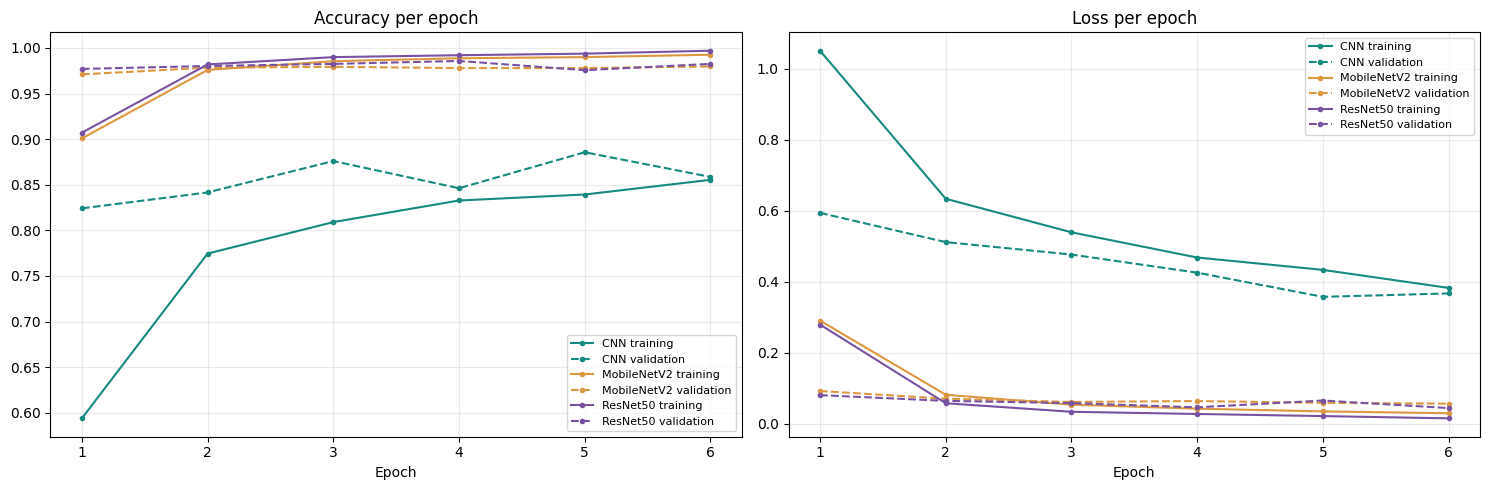

In [ ]:
histories = {name: pd.read_csv(folder_hasil / f'history_{name}.csv') for name in nama_model}
fig, axes = plt.subplots(1, 2, figsize=(15, 5))
colors = {'CNN':'#168a80', 'MobileNetV2':'#dc9840', 'ResNet50':'#7852a1'}
for name in nama_model:
    h = histories[name]
    epoch = h['epoch'] + 1
    for axis, key in zip(axes, ['accuracy', 'loss']):
        axis.plot(epoch, h[key], color=colors[name], marker='o', markersize=3, label=f'{name} training')
        axis.plot(epoch, h['val_' + key], color=colors[name], marker='o', markersize=3, linestyle='--', label=f'{name} validation')
for ax, title in zip(axes, ['Accuracy per epoch', 'Loss per epoch']):
    ax.set(title=title, xlabel='Epoch'); ax.grid(alpha=0.25); ax.legend(fontsize=8)
fig.tight_layout()
fig.savefig(folder_hasil / 'grafik_accuracy_loss.png', dpi=180, bbox_inches='tight')
plt.show()

## 10. Evaluasi per kelas dan confusion matrix
Confusion matrix dan laporan per kelas untuk model terpilih membantu melihat kelas mana yang paling sering tertukar.

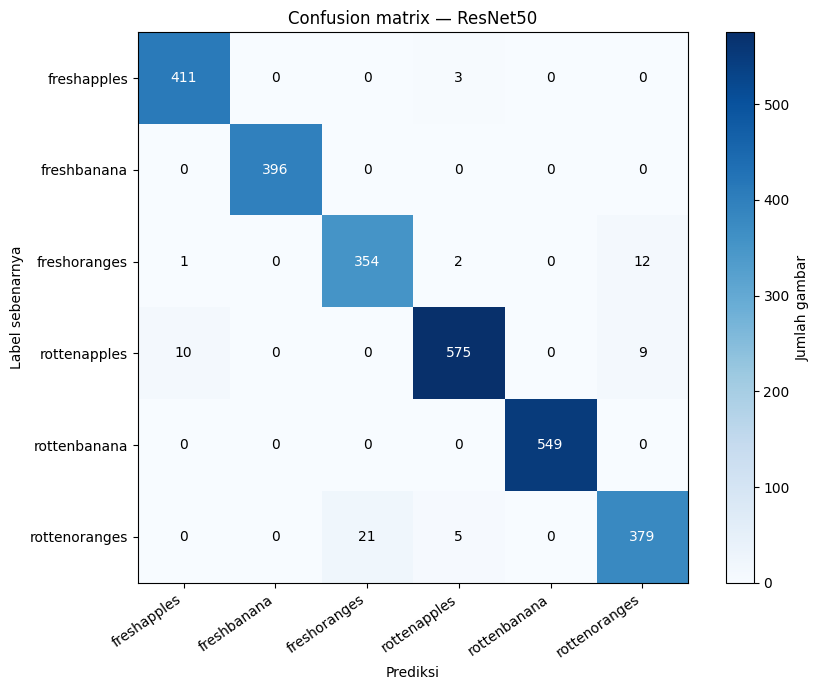

,precision,recall,f1-score,support
freshapples,0.9739,0.9928,0.9833,414.0000
freshbanana,1.0000,1.0000,1.0000,396.0000
freshoranges,0.9440,0.9593,0.9516,369.0000
rottenapples,0.9829,0.9680,0.9754,594.0000
rottenbanana,1.0000,1.0000,1.0000,549.0000
rottenoranges,0.9475,0.9358,0.9416,405.0000
accuracy,0.9769,0.9769,0.9769,0.9769
macro avg,0.9747,0.9760,0.9753,2727.0000
weighted avg,0.9769,0.9769,0.9769,2727.0000


In [ ]:
model_pilihan = muat_model(terbaik)
truth, prediksi = [], []
for images, labels in untuk_model(test_ds, terbaik):
    probability = model_pilihan(images, training=False).numpy()
    truth.extend(labels.numpy().tolist())
    prediksi.extend(np.argmax(probability, axis=1).tolist())
cm = confusion_matrix(truth, prediksi, labels=list(range(len(class_names))))
laporan = classification_report(truth, prediksi, labels=list(range(len(class_names))),
                                target_names=class_names, output_dict=True, zero_division=0)
pd.DataFrame(laporan).transpose().to_csv(folder_hasil / 'laporan_klasifikasi_model_terpilih.csv')
fig, ax = plt.subplots(figsize=(9, 7))
im = ax.imshow(cm, cmap='Blues'); fig.colorbar(im, ax=ax, label='Jumlah gambar')
ax.set(xticks=np.arange(6), yticks=np.arange(6), xticklabels=class_names, yticklabels=class_names,
       xlabel='Prediksi', ylabel='Label sebenarnya', title=f'Confusion matrix — {terbaik}')
plt.setp(ax.get_xticklabels(), rotation=35, ha='right')
for i in range(6):
    for j in range(6):
        ax.text(j, i, str(cm[i, j]), ha='center', va='center', color='white' if cm[i, j] > cm.max()/2 else 'black')
fig.tight_layout(); fig.savefig(folder_hasil / 'confusion_matrix.png', dpi=180, bbox_inches='tight'); plt.show()
display(pd.DataFrame(laporan).transpose().round(4))

## 11. Diagram arsitektur model terpilih
Diagram merangkum lapisan utama untuk bahan presentasi. Tahap preprocessing berada di pipeline sebelum input model. Detail lengkap model juga disimpan sebagai teks.

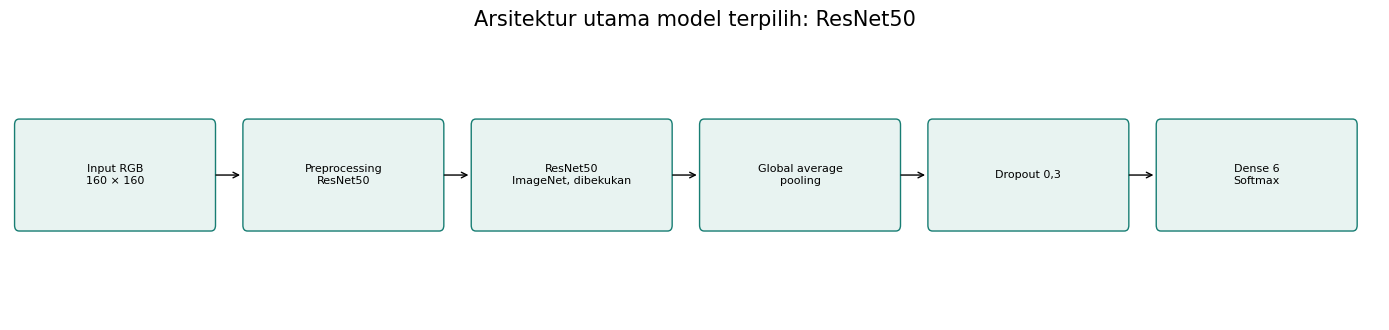

In [ ]:
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
if terbaik == 'CNN':
    nodes = ['Input RGB\n160 × 160', 'Skala\n0–1', 'Conv 32 + pool', 'Conv 64 + pool',
             'Conv 128 + pool', 'Global average\npooling', 'Dropout 0,3', 'Dense 128\nReLU', 'Dense 6\nSoftmax']
else:
    nodes = ['Input RGB\n160 × 160', 'Preprocessing\n' + terbaik,
             terbaik + '\nImageNet, dibekukan', 'Global average\npooling', 'Dropout 0,3', 'Dense 6\nSoftmax']
fig, ax = plt.subplots(figsize=(14, 3.4))
ax.set_xlim(0, len(nodes)); ax.set_ylim(0, 1); ax.axis('off')
for i, node in enumerate(nodes):
    ax.add_patch(FancyBboxPatch((i+0.04, 0.33), 0.84, 0.35, boxstyle='round,pad=0.02',
                               facecolor='#e8f3f1', edgecolor='#177d73'))
    ax.text(i+0.46, 0.505, node, ha='center', va='center', fontsize=8)
    if i < len(nodes)-1:
        ax.add_patch(FancyArrowPatch((i+0.89, 0.505), (i+1.02, 0.505), arrowstyle='->', mutation_scale=10))
ax.set_title(f'Arsitektur utama model terpilih: {terbaik}', fontsize=15, pad=5)
fig.tight_layout(); fig.savefig(folder_hasil / 'diagram_arsitektur_terbaik.png', dpi=200, bbox_inches='tight'); plt.show()
with (folder_hasil / 'ringkasan_arsitektur_terbaik.txt').open('w', encoding='utf-8') as f:
    model_pilihan.summary(print_fn=lambda line: f.write(line + '\n'))

## 12. Analisis otomatis berdasarkan hasil aktual
Narasi berikut menggunakan hasil yang benar-benar dihasilkan, bukan perkiraan. Interpretasi tetap perlu diperiksa kelompok, terutama kemungkinan kebocoran visual yang belum terdeteksi dan keterbatasan perbandingan pretrained versus dari awal.

In [ ]:
pilihan = tabel.set_index('Model').loc[terbaik]
tercepat = tabel.sort_values('Inference Time (ms)').iloc[0]
terkecil = tabel.sort_values('Parameter').iloc[0]
analisis = [
    f"Model terpilih adalah {terbaik} berdasarkan validation accuracy {pilihan['Validation Accuracy']:.2%} dan validation loss {pilihan['Validation Loss']:.4f}. Kriteria pemilihan ditetapkan sebelum melihat hasil testing.",
    f"Pada data testing, {terbaik} memperoleh accuracy {pilihan['Accuracy']:.2%} dan loss {pilihan['Loss']:.4f}. Perbedaan validation dan testing dapat terjadi karena kedua subset berisi kelompok gambar yang berbeda."
]
for nama in nama_model:
    baris = tabel.set_index('Model').loc[nama]
    h = histories[nama]
    epoch_terbaik = h.loc[h['val_loss'].idxmin()]
    gap = float(epoch_terbaik['accuracy'] - epoch_terbaik['val_accuracy'])
    selisih_akhir = float(h['val_loss'].tail(min(5, len(h))).max() - h['val_loss'].tail(min(5, len(h))).min())
    analisis.append(
        f"{nama}: test accuracy {baris['Accuracy']:.2%}, validation accuracy {baris['Validation Accuracy']:.2%}, "
        f"validation loss {baris['Validation Loss']:.4f}, {len(h)} epoch, dan "
        f"{int(baris['Parameter']):,} parameter total. Selisih training-validation accuracy pada epoch checkpoint "
        f"adalah {gap:+.2%}; rentang val_loss pada hingga lima epoch terakhir {selisih_akhir:.4f}. "
        'Rentang ini hanya deskripsi satu run; jumlah epoch yang berbeda dan augmentasi perlu dipertimbangkan saat menilai kestabilan.'
    )
analisis.extend([
    f"Dalam pengukuran runtime ini, {tercepat['Model']} memiliki rata-rata inference time terendah ({tercepat['Inference Time (ms)']:.2f} ms/gambar); {terkecil['Model']} memiliki parameter total paling sedikit ({int(terkecil['Parameter']):,}). Hasil waktu tergantung perangkat dan tidak mencakup pembacaan gambar.",
    'CNN dilatih dari awal, sedangkan MobileNetV2 dan ResNet50 memakai bobot ImageNet dengan lapisan dasar dibekukan. Perbedaan hasil dapat dipengaruhi bobot awal, arsitektur, augmentasi, dan konfigurasi pelatihan; percobaan ini tidak mengisolasi satu penyebab.',
    'Pembagian berbasis nama asal mencegah versi dengan nama asal sama berada pada beberapa subset. Foto yang mirip dengan nama berbeda masih bisa menyebabkan kebocoran; evaluasi pada foto baru yang independen diperlukan untuk menilai generalisasi.',
    'Pelatihan dibatasi maksimal 6 epoch dan patience 2 untuk mengurangi waktu. Batas ini dapat menyebabkan underfitting; akurasi dan keunggulan model perlu ditafsirkan dalam batas eksperimen ini. Early stopping dan checkpoint memantau validation loss.'
])
for text in analisis:
    print('•', text, '\n')
(folder_hasil / 'analisis_hasil.txt').write_text('\n\n'.join(analisis), encoding='utf-8')

• Model terpilih adalah ResNet50 berdasarkan validation accuracy 98.26% dan validation loss 0.0442. Kriteria pemilihan ditetapkan sebelum melihat hasil testing. 

• Pada data testing, ResNet50 memperoleh accuracy 97.69% dan loss 0.0590. Perbedaan validation dan testing dapat terjadi karena kedua subset berisi kelompok gambar yang berbeda. 

• CNN: test accuracy 87.09%, validation accuracy 88.57%, validation loss 0.3574, 6 epoch, dan 110,534 parameter total. Selisih training-validation accuracy pada epoch checkpoint adalah -4.64%; rentang val_loss pada hingga lima epoch terakhir 0.1541. Rentang ini hanya deskripsi satu run; jumlah epoch yang berbeda dan augmentasi perlu dipertimbangkan saat menilai kestabilan. 

• MobileNetV2: test accuracy 98.02%, validation accuracy 97.98%, validation loss 0.0566, 6 epoch, dan 2,265,670 parameter total. Selisih training-validation accuracy pada epoch checkpoint adalah +1.28%; rentang val_loss pada hingga lima epoch terakhir 0.0139. Rentang ini hanya d

2452

## 13. Periksa hasil untuk pengumpulan
Setelah semua selesai, folder Drive berisi file model, riwayat, CSV pembagian, tabel perbandingan, grafik, diagram, confusion matrix, dan analisis. Simpan notebook dengan output di Google Drive dan atur akses link sesuai instruksi aslab. PPT masih perlu dibuat oleh kelompok.

In [ ]:
files_required = ['CNN_terbaik.keras', 'MobileNetV2_terbaik.keras', 'ResNet50_terbaik.keras',
                  'history_CNN.csv', 'history_MobileNetV2.csv', 'history_ResNet50.csv',
                  'train.csv', 'validation.csv', 'test.csv', 'tabel_perbandingan.csv',
                  'grafik_accuracy_loss.png', 'diagram_arsitektur_terbaik.png', 'analisis_hasil.txt']
for name in files_required:
    path = folder_hasil / name
    print(('OK   ' if path.is_file() and path.stat().st_size > 0 else 'BELUM'), name)
if not all((folder_hasil / n).is_file() and (folder_hasil / n).stat().st_size > 0 for n in files_required):
    raise RuntimeError('Ada hasil yang belum tersedia. Periksa sel sebelumnya.')
print('Semua hasil utama tersedia di:', folder_hasil)

OK    CNN_terbaik.keras
OK    MobileNetV2_terbaik.keras
OK    ResNet50_terbaik.keras
OK    history_CNN.csv
OK    history_MobileNetV2.csv
OK    history_ResNet50.csv
OK    train.csv
OK    validation.csv
OK    test.csv
OK    tabel_perbandingan.csv
OK    grafik_accuracy_loss.png
OK    diagram_arsitektur_terbaik.png
OK    analisis_hasil.txt
Semua hasil utama tersedia di: /content/drive/MyDrive/UAS_AI/buah_cepat_resume_daf3a93e2d
